In [1]:
# ======================================================================
# ЭКЗАМЕНАЦИОННАЯ ЗАДАЧА №01: ОЦЕНКА ЭКОНОМИЧЕСКОЙ ЭФФЕКТИВНОСТИ ВНЕДРЕНИЯ ОБЛАЧНОЙ CRM
# ======================================================================
# Дата: 2026-10-18
# Студент: [ФИО]
# Группа: [№ группы]
# ======================================================================

# Экзаменационная задача: внедрение облачной CRM («ТехноПром»)
Структура ноутбука: исходные данные → расчёты → анализ результатов → выводы и рекомендации.

## 1. ИСХОДНЫЕ ДАННЫЕ

In [2]:
# 1.1. Параметры проекта
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq

plt.rcParams['figure.figsize'] = (11, 5)
plt.rcParams['font.size'] = 10

n_managers = 15              # менеджеров в отделе продаж, чел.
salary = 120_000             # средняя зарплата менеджера, руб./мес.
time_saving = 0.20           # экономия времени на рутине после внедрения CRM
routine_share = 0.30         # доля рабочего времени на рутину (без CRM)
sales_growth = 0.08          # рост продаж после внедрения, в год
turnover = 72_000_000        # текущий годовой оборот отдела, руб.
license_per_user = 24_000    # стоимость облачной CRM, руб./чел. в год
adaptation_months = 1        # месяцев на обучение и адаптацию
horizon = 3                  # горизонт оценки, лет
discount_rate = 0.12         # ставка дисконтирования
tax_rate = 0.20              # налог на прибыль

params = pd.Series({
    'Менеджеров, чел.': n_managers,
    'Зарплата, руб./мес.': salary,
    'Экономия времени на рутине': time_saving,
    'Доля рутины в рабочем времени': routine_share,
    'Рост продаж, %/год': sales_growth * 100,
    'Оборот отдела, руб./год': turnover,
    'Лицензия CRM, руб./чел. в год': license_per_user,
    'Адаптация, мес.': adaptation_months,
    'Горизонт, лет': horizon,
    'Ставка дисконтирования': discount_rate,
    'Налог на прибыль': tax_rate,
})
print(params.to_string())

Менеджеров, чел.                       15.00
Зарплата, руб./мес.                120000.00
Экономия времени на рутине              0.20
Доля рутины в рабочем времени           0.30
Рост продаж, %/год                      8.00
Оборот отдела, руб./год          72000000.00
Лицензия CRM, руб./чел. в год       24000.00
Адаптация, мес.                         1.00
Горизонт, лет                           3.00
Ставка дисконтирования                  0.12
Налог на прибыль                        0.20


In [3]:
# 1.2. Справочные данные: фонд оплаты труда отдела
payroll_month = n_managers * salary
payroll_year = payroll_month * 12
print(f'ФОТ отдела продаж: {payroll_month:,.0f} руб./мес., {payroll_year:,.0f} руб./год')

ФОТ отдела продаж: 1,800,000 руб./мес., 21,600,000 руб./год


### 1.3. Дополнительные условия и принятые допущения
1. Потери на адаптации = один месяц фонда оплаты труда отдела (менеджеры в этот месяц не работают в обычном режиме). Это разовые затраты нулевого периода, налоговой экономии они не дают (в бухучёте отдельным расходом не являются).
2. Лицензии оплачиваются в конце каждого года, платёж включается в расходы и уменьшает налогооблагаемую прибыль.
3. Экономия времени менеджеров считается как высвобождаемая стоимость рабочего времени (ФОТ × доля рутины × экономия времени).
4. Рост продаж 8% берётся от текущего оборота и не накапливается по годам. В условии не задана маржа, поэтому в базовом расчёте «дополнительный доход» принимается как прирост прибыли до налога. Допущение проверяется в разделе 3 (влияние маржи).
5. Денежные потоки относятся к концу периода, период 0 — момент внедрения.

## 2. РАСЧЁТЫ

In [4]:
# 2.1. Прямой эффект от внедрения CRM
# экономия на заработной плате за счёт автоматизации рутины (в год)
salary_saving = payroll_year * routine_share * time_saving
# дополнительный доход от роста продаж (в год)
extra_income = turnover * sales_growth

print(f'Экономия ФОТ:              {salary_saving:>14,.0f} руб./год')
print(f'Дополнительный доход:      {extra_income:>14,.0f} руб./год')
print(f'Прямой эффект до налога:   {salary_saving + extra_income:>14,.0f} руб./год')

Экономия ФОТ:                   1,296,000 руб./год
Дополнительный доход:           5,760,000 руб./год
Прямой эффект до налога:        7,056,000 руб./год


In [5]:
# 2.2. Затраты на внедрение
licenses_year = n_managers * license_per_user          # лицензии за год
licenses_total = licenses_year * horizon                # лицензии за 3 года
adaptation_loss = payroll_month * adaptation_months     # потери при обучении

print(f'Лицензии за год:           {licenses_year:>12,.0f} руб.')
print(f'Лицензии за {horizon} года:        {licenses_total:>12,.0f} руб.')
print(f'Потери на адаптации:       {adaptation_loss:>12,.0f} руб.')
print(f'Затраты проекта всего:     {licenses_total + adaptation_loss:>12,.0f} руб.')

Лицензии за год:                360,000 руб.
Лицензии за 3 года:           1,080,000 руб.
Потери на адаптации:          1,800,000 руб.
Затраты проекта всего:        2,880,000 руб.


In [6]:
# 2.3. Финансовые показатели эффективности
years = list(range(0, horizon + 1))

def project_cash_flows(salary_eff, income_eff):
    """Денежные потоки проекта по годам при заданном эффекте."""
    pretax = salary_eff + income_eff - licenses_year    # прибыль до налога
    tax = pretax * tax_rate
    net_profit = pretax - tax                           # прирост чистой прибыли
    flows = [-adaptation_loss] + [net_profit] * horizon
    return flows, pretax, tax, net_profit

cash_flows, pretax_gain, tax_amount, net_gain = project_cash_flows(
    salary_saving, extra_income)

table = pd.DataFrame({
    'Год': years,
    'Эффект до налога': [0] + [salary_saving + extra_income] * horizon,
    'Лицензии': [0] + [-licenses_year] * horizon,
    'Налог на прибыль': [0] + [-tax_amount] * horizon,
    'Адаптация': [-adaptation_loss] + [0] * horizon,
    'Денежный поток': cash_flows,
})
table['Дисконт-фактор'] = [1 / (1 + discount_rate) ** t for t in years]
table['Дисконтированный ДП'] = table['Денежный поток'] * table['Дисконт-фактор']
table['Накопленный ДП'] = table['Денежный поток'].cumsum()
table['Накопленный дисконтированный ДП'] = table['Дисконтированный ДП'].cumsum()
print(table.round(3).to_string(index=False))

 Год  Эффект до налога  Лицензии  Налог на прибыль  Адаптация  Денежный поток  Дисконт-фактор  Дисконтированный ДП  Накопленный ДП  Накопленный дисконтированный ДП
   0               0.0         0               0.0   -1800000      -1800000.0           1.000         -1800000.000      -1800000.0                     -1800000.000
   1         7056000.0   -360000        -1339200.0          0       5356800.0           0.893          4782857.143       3556800.0                      2982857.143
   2         7056000.0   -360000        -1339200.0          0       5356800.0           0.797          4270408.163       8913600.0                      7253265.306
   3         7056000.0   -360000        -1339200.0          0       5356800.0           0.712          3812864.431      14270400.0                     11066129.738


In [7]:
# Показатели: NPV, сроки окупаемости, ROI, PI, IRR
def npv(flows, rate):
    return sum(cf / (1 + rate) ** t for t, cf in enumerate(flows))

def payback(flows):
    """Срок окупаемости (лет) с линейной интерполяцией внутри года."""
    total = 0
    for t, cf in enumerate(flows):
        prev = total
        total += cf
        if total >= 0 and t > 0:
            return (t - 1) + (-prev) / cf
    return float('inf')

npv_value = npv(cash_flows, discount_rate)
discounted_flows = [cf / (1 + discount_rate) ** t for t, cf in enumerate(cash_flows)]
simple_pb = payback(cash_flows)
discounted_pb = payback(discounted_flows)
invest = adaptation_loss
roi_value = (sum(cash_flows[1:]) - invest) / invest * 100        # ROI, %
pi_value = sum(discounted_flows[1:]) / invest                   # индекс доходности
irr_value = brentq(lambda r: npv(cash_flows, r), 0.0, 50.0)     # IRR

print(f'Прирост чистой прибыли в год: {net_gain:,.0f} руб.')
print(f'NPV (r = {discount_rate:.0%}):       {npv_value:,.0f} руб.')
print(f'Простой срок окупаемости:    {simple_pb:.2f} года ({simple_pb * 12:.1f} мес.)')
print(f'Дисконтированный срок:       {discounted_pb:.2f} года ({discounted_pb * 12:.1f} мес.)')
print(f'ROI за {horizon} года:              {roi_value:,.0f} %')
print(f'Индекс доходности PI:        {pi_value:.2f}')
print(f'IRR:                         {irr_value:.0%}')

Прирост чистой прибыли в год: 5,356,800 руб.
NPV (r = 12%):       11,066,130 руб.
Простой срок окупаемости:    0.34 года (4.0 мес.)
Дисконтированный срок:       0.38 года (4.5 мес.)
ROI за 3 года:              793 %
Индекс доходности PI:        7.15
IRR:                         293%


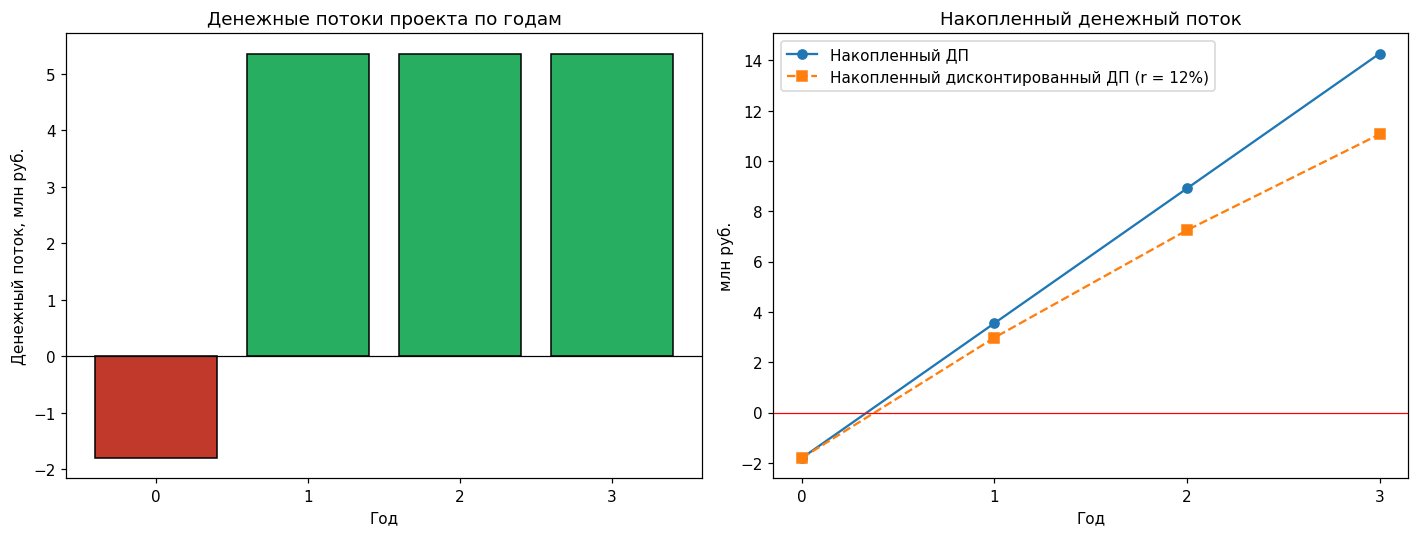

In [8]:
# 2.4. Визуализация результатов
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

colors = ['#c0392b' if cf < 0 else '#27ae60' for cf in cash_flows]
axes[0].bar(years, np.array(cash_flows) / 1e6, color=colors, edgecolor='black')
axes[0].axhline(0, color='black', linewidth=0.8)
axes[0].set_title('Денежные потоки проекта по годам')
axes[0].set_xlabel('Год')
axes[0].set_ylabel('Денежный поток, млн руб.')
axes[0].set_xticks(years)

axes[1].plot(years, table['Накопленный ДП'] / 1e6, 'o-', label='Накопленный ДП')
axes[1].plot(years, table['Накопленный дисконтированный ДП'] / 1e6, 's--',
             label='Накопленный дисконтированный ДП (r = 12%)')
axes[1].axhline(0, color='red', linewidth=0.8)
axes[1].set_title('Накопленный денежный поток')
axes[1].set_xlabel('Год')
axes[1].set_ylabel('млн руб.')
axes[1].set_xticks(years)
axes[1].legend()
plt.tight_layout()
plt.show()

## 3. АНАЛИЗ РЕЗУЛЬТАТОВ

In [9]:
# 3.1. Интерпретация: структура эффекта и чувствительность к допущениям
def scenario_npv(realization, margin, growth=sales_growth):
    """NPV при доле реализации эффекта и марже дополнительной выручки."""
    flows, *_ = project_cash_flows(salary_saving * realization,
                                   turnover * growth * realization * margin)
    return npv(flows, discount_rate)

realizations = [1.0, 0.75, 0.5, 0.25]
margins = [1.0, 0.30, 0.15]
sens = pd.DataFrame(
    {f'маржа {int(m * 100)}%': [scenario_npv(s, m) / 1e6 for s in realizations]
     for m in margins},
    index=[f'реализация {int(s * 100)}%' for s in realizations])
print('NPV, млн руб. (строки — доля реализованного эффекта, столбцы — маржа допдохода):')
print(sens.round(2).to_string())

# доля эффекта, при которой NPV = 0, для разных маржинальностей
break_even = {m: brentq(lambda s: scenario_npv(s, m), 0.0, 1.0) for m in margins}
for m, s in break_even.items():
    print(f'Маржа {m:.0%}: NPV = 0 при реализации эффекта {s:.0%}')

NPV, млн руб. (строки — доля реализованного эффекта, столбцы — маржа допдохода):
                 маржа 100%  маржа 30%  маржа 15%
реализация 100%       11.07       3.32       1.66
реализация 75%         7.68       1.87       0.62
реализация 50%         4.29       0.41      -0.42
реализация 25%         0.90      -1.04      -1.45
Маржа 100%: NPV = 0 при реализации эффекта 18%
Маржа 30%: NPV = 0 при реализации эффекта 43%
Маржа 15%: NPV = 0 при реализации эффекта 60%


Не внедрять                                0.00
Базовый (по условию)                      11.07
Эффект 50%, маржа 30%                      0.41
Парадокс Солоу: 25% эффекта, маржа 30%    -1.04
Накопительный рост продаж 8% в год        22.40


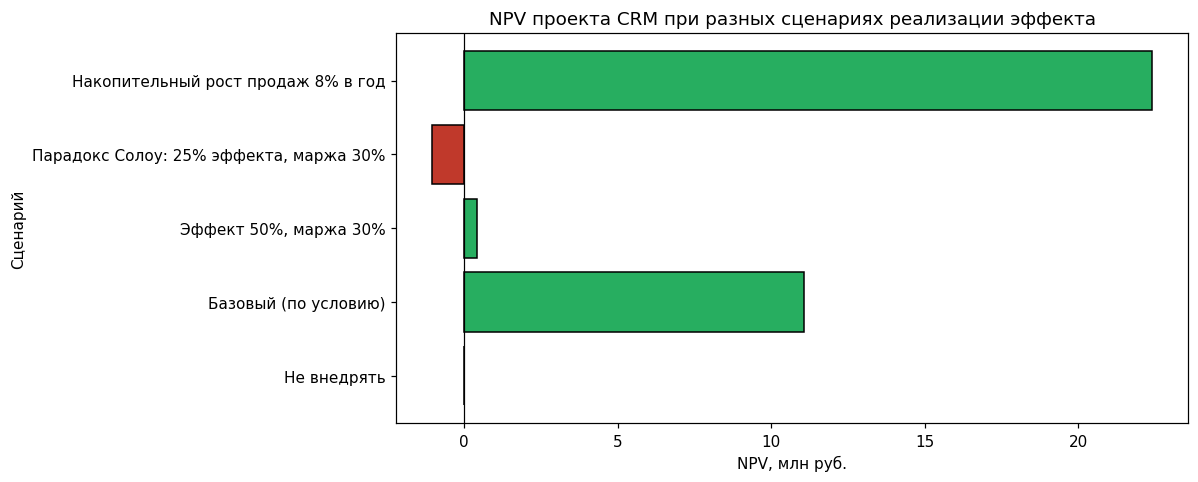

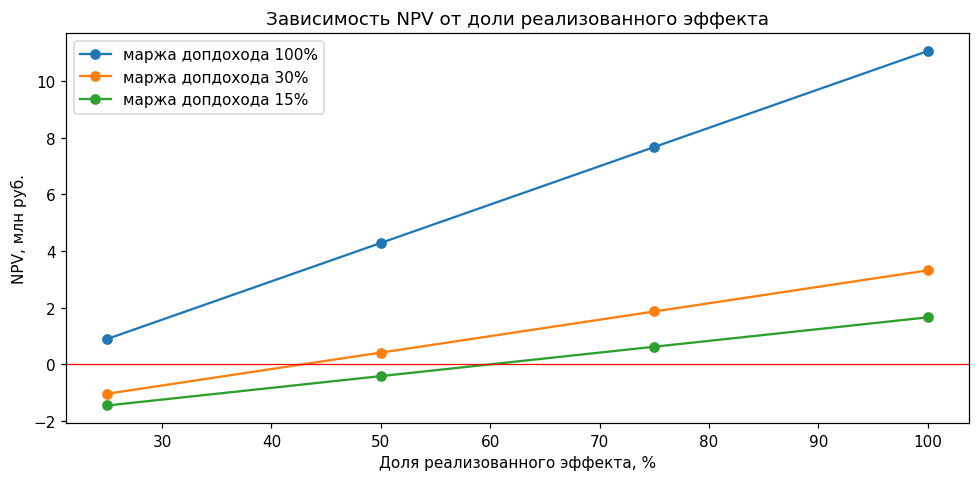

In [10]:
# 3.2. Сравнение с альтернативными вариантами
# (а) отказ от проекта: NPV = 0; (б) базовый сценарий; (в) консервативный;
# (г) «парадокс Солоу»: освободившееся время не превращается в продажи
scenarios = {
    'Не внедрять': 0.0,
    'Базовый (по условию)': scenario_npv(1.0, 1.0),
    'Эффект 50%, маржа 30%': scenario_npv(0.5, 0.30),
    'Парадокс Солоу: 25% эффекта, маржа 30%': scenario_npv(0.25, 0.30),
    'Накопительный рост продаж 8% в год':
        npv([-adaptation_loss] + [
            ((salary_saving + turnover * ((1 + sales_growth) ** t - 1)
              - licenses_year) * (1 - tax_rate)) for t in range(1, horizon + 1)],
            discount_rate),
}
comparison = pd.Series(scenarios) / 1e6
print(comparison.round(2).to_string())

fig, ax = plt.subplots(figsize=(11, 4.5))
bar_colors = ['#7f8c8d' if v == 0 else '#27ae60' if v > 0 else '#c0392b'
              for v in comparison]
ax.barh(comparison.index, comparison.values, color=bar_colors, edgecolor='black')
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('NPV проекта CRM при разных сценариях реализации эффекта')
ax.set_xlabel('NPV, млн руб.')
ax.set_ylabel('Сценарий')
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 4.5))
for m in margins:
    ax.plot([s * 100 for s in realizations], [scenario_npv(s, m) / 1e6 for s in realizations],
            'o-', label=f'маржа допдохода {m:.0%}')
ax.axhline(0, color='red', linewidth=0.8)
ax.set_title('Зависимость NPV от доли реализованного эффекта')
ax.set_xlabel('Доля реализованного эффекта, %')
ax.set_ylabel('NPV, млн руб.')
ax.legend()
plt.tight_layout()
plt.show()

RESULTS = {'salary_saving': salary_saving, 'extra_income': extra_income, 'licenses_year': licenses_year,
           'licenses_total': licenses_total, 'adaptation_loss': adaptation_loss, 'pretax': pretax_gain,
           'tax': tax_amount, 'net_gain': net_gain, 'npv': npv_value, 'payback': simple_pb,
           'disc_payback': discounted_pb, 'roi': roi_value, 'pi': pi_value, 'irr': irr_value,
           'be30': break_even[0.30], 'be15': break_even[0.15], 'solow': scenarios['Парадокс Солоу: 25% эффекта, маржа 30%'],
           'cum': scenarios['Накопительный рост продаж 8% в год'], 'half30': scenarios['Эффект 50%, маржа 30%']}

### 3.3. Нематериальные эффекты (п. 4 задания)
Нематериальные выгоды CRM, которые не попали в денежный поток:
- единая клиентская база и история контактов: менеджер не «уносит» клиентов при увольнении, проще передавать клиентов между сотрудниками;
- прозрачная воронка продаж и прогноз выручки, управление по показателям, а не по ощущениям;
- рост качества обслуживания и лояльности клиентов (напоминания, быстрые ответы, единые стандарты);
- ускорение адаптации новых менеджеров, база знаний, шаблоны коммерческих предложений;
- данные для аналитики (ABC-анализ клиентов, причины отказов, эффективность каналов).

**Парадокс производительности Солоу** («компьютеры видны везде, кроме статистики производительности») означает, что вложения в ИТ не обязательно дают рост отдачи сами по себе. Для CRM это значит: сэкономленное время менеджеров даёт деньги только в том случае, если его реально превратили в звонки, встречи и сделки (или сократили штат). Если менеджеры вносят данные «для галочки», дублируют работу в Excel, сопротивляются новому инструменту, то фактический эффект будет заметно ниже расчётного. Поэтому в расчёте выше показаны сценарии с частичной реализацией эффекта, а в рекомендациях заложены меры организационного внедрения (обучение, KPI на заполнение CRM, пилот).

## 4. ВЫВОДЫ И РЕКОМЕНДАЦИИ

### 4.1. Ключевые выводы
1. **Прямой эффект** составляет 7 056 000 руб. в год до налога: экономия ФОТ 1 296 000 руб. (6% фонда оплаты труда отдела: 30% времени на рутину × 20% экономии) и дополнительный доход от роста продаж 5 760 000 руб. Затраты на лицензии — 360 000 руб. в год (1 080 000 руб. за 3 года), потери на адаптации — 1 800 000 руб.
2. **Прирост чистой прибыли** после налога 20% — 5 356 800 руб. ежегодно. **NPV проекта = 11 066 130 руб.** (r = 12%, горизонт 3 года) — проект создаёт стоимость, а не только окупается.
3. **Простой срок окупаемости** — 0,34 года (около 4 мес.), дисконтированный — 0,38 года; ROI = 793%, индекс доходности PI = 7,1, IRR существенно выше ставки дисконтирования. Такие значения нетипичны для ИТ-проекта и говорят не о «сверхэффективности», а о том, что вложения очень малы по сравнению с эффектом (облачная модель без капитальных затрат).
4. **Главный источник эффекта — рост продаж** (82% прямого эффекта), и он же самый неопределённый: в условии не задана маржа, поэтому дополнительная выручка в базовом расчёте приравнена к прибыли. При марже 30% NPV остаётся положительным, при реализации эффекта лишь на 43% проект выходит на нулевой NPV.
5. **Устойчивость:** при реализации половины эффекта и марже 30% NPV = 0,41 млн руб. (всё ещё положителен), а в сценарии «парадокса Солоу» (реализовано 25% эффекта, маржа 30%) NPV = −1,04 млн руб. — проект уходит в минус. Порог безубыточности: реализация 43% расчётного эффекта при марже 30% и 60% при марже 15%. Следовательно, проект целесообразен при условии, что организационно обеспечено не менее половины расчётного эффекта.

### 4.2. Практические рекомендации
1. **Внедрять CRM**, но стартовать с пилота на 3–5 менеджерах на 1–2 месяца: цель — подтвердить высвобождение времени и конверсию, до масштабирования на весь отдел.
2. **Зафиксировать KPI проекта:** доля сделок, заведённых в CRM; время на рутинные операции (хронометраж до/после); конверсия воронки; средний цикл сделки. Без измерения реализованного эффекта оценка остаётся прогнозной.
3. **Сдерживать парадокс Солоу:** обязательное обучение, назначение ответственного за данные в CRM, привязка части премии к качеству ведения базы, отказ от параллельных Excel-таблиц.
4. **Консервативный план:** в бюджетных документах использовать сценарий с реализацией эффекта 50% и маржой дополнительной выручки 30% (NPV = 0,41 млн руб.), а базовый расчёт считать верхней границей.
5. **Договорные меры:** фиксировать цену лицензий на 3 года, предусмотреть выгрузку данных при смене поставщика (риск привязки к вендору), проверить размещение персональных данных клиентов в РФ (152-ФЗ).